# Stage 1.5: geometry and per-face graphlet degree vectors

This experiment combines surface geometry with local topology for classifying
B-rep faces. A Face CNN represents each face's surface grid, while a graphlet
degree vector describes its structural roles in small connected subgraphs.
The two feature sets are concatenated and passed to a two-layer classifier.

The experiment is organised into six sections:

1. [Setup and configuration](#1-setup-and-configuration)
2. [Data pipeline](#2-data-pipeline)
3. [Model](#3-model)
4. [Training pipeline](#4-training-pipeline)
5. [Evaluation pipeline](#5-evaluation-pipeline)
6. [Results and plots](#6-results-and-plots)

We retain the complete official dataset partitions, with the following roles:

| Split | Role in the experiment |
| --- | --- |
| `train` | Fitting feature statistics, optimising parameters, and measuring the final training fit |
| `validation` | Monitoring loss and accuracy after each epoch and evaluating the final model |
| `test` | Assessing the final model on held-out data after training |

The reported model is taken from the final configured epoch. Feature scaling
is fitted on training faces only and applied unchanged to validation and test.
Test scores are excluded from training and checkpoint selection. All solids,
faces, and final partial batches are included.

The **gnn_project** kernel is used, with sections executed in order. Graphlet
features are fixed preprocessing; the classifier and, in joint mode, the CNN
are learned. The model does not use learned graph message passing or a graph-level classifier.

## 1. Setup and configuration

The experiment supports graphlets with two to four nodes (15 node-orbit
features) or two to five nodes (73 features). These dimensions count structural
roles within graphlets rather than the number of distinct graphlet types.

The default configuration uses joint training with four-node graphlets,
20 epochs, Adam at a learning rate of 0.001, and batches of 128 solids. Frozen
mode trains the classifier on cached geometry embeddings; joint mode also
fine-tunes the Face CNN. Each size and mode has a separate results directory.
A fixed seed and deterministic settings support reproducibility. Repeated runs
replace files with the same names.

In [1]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json

import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import (
    seed_everything, save_training_checkpoint, load_training_checkpoint,
)
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.classifier import Classifier
from uvnet_project.graphlets import graphlet_degree_vectors, orbit_catalog
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

from uvnet_project.geometry_graphlet import FaceGraphletBatch, GeometryGraphletClassifier

In [2]:
seed = 0
deterministic = True
# None starts a new seeded run. To resume, set the completed epoch checkpoint:
# resume_checkpoint = DATA_DIR.parent.parent / "results/graphlet4_frozen_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)
project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "frozen"  # "frozen" or "joint"; rerun from the top after changing
if training_mode not in ("frozen", "joint"):
    raise ValueError("training_mode must be frozen or joint.")
max_graphlet_nodes = 4  # 4 or 5: 15 or 73 node-orbit features
if max_graphlet_nodes not in (4, 5):
    raise ValueError("max_graphlet_nodes must be 4 or 5.")
graphlet_dim = 15 if max_graphlet_nodes == 4 else 73
num_epochs = 20
batch_size = 128  # solids per training batch
learning_rate = 0.001
run_name = f"graphlet{max_graphlet_nodes}_{training_mode}_run_01"
run_dir = project_dir / "results" / run_name
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


if min(graphlet_dim, num_epochs, batch_size) < 1:
    raise ValueError("Dimensions, epoch count and batch/checkpoint sizes must be positive.")

SPLITS = ("train", "validation", "test")
print("Device:", device, "Mode:", training_mode, "Orbit features:", graphlet_dim)

Device: cuda Mode: frozen Orbit features: 15


### 1.1 Pretrained geometry encoder

Both modes start from the same completed geometry-only encoder checkpoint.
The checkpoint supplies model dimensions and initial CNN weights. Its hash
identifies the source weights in feature caches and training checkpoints.

A fixed copy of the encoder prepares frozen embeddings. Joint mode creates
a separate trainable encoder from the same initial weights. With the default
64-dimensional embedding, the classifier input width is 79 or 137.

In [3]:
if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"The pretrained geometry checkpoint is required: {baseline_checkpoint}")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim = config["embedding_dim"]
hidden_dim = config["hidden_dim"]
num_classes = config["num_classes"]
in_channels = config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
print("Device:", device, "Classifier input:", embedding_dim + graphlet_dim)


# The first module in the saved sequential model is the face encoder.
cnn_state = {key.removeprefix("0."): value
             for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()  # used only to prepare frozen-mode embeddings

Device: cuda Classifier input: 79


c:\Users\KaiSheng\anaconda3\envs\gnn_project\Lib\site-packages\torch\_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## 2. Data pipeline

### 2.1 Dataset partitions

Sample IDs are read from the official split file. Each partition is checked
for empty or duplicate entries and overlap with the other partitions. Original
sample order is retained to map saved predictions back to their solids and faces.

In [4]:
official_splits = _load_splits()
split_ids = {}
seen_ids = set()
for split in SPLITS:
    ids = list(official_splits[split])
    if not ids:
        raise ValueError(f"The {split} split is empty.")
    if len(ids) != len(set(ids)):
        raise ValueError(f"Duplicate sample IDs in {split}.")
    overlap = seen_ids.intersection(ids)
    if overlap:
        raise ValueError(f"The {split} split overlaps an earlier split: {sorted(overlap)[:5]}")
    split_ids[split] = ids
    seen_ids.update(ids)

display(pd.DataFrame([
    {"split": split, "solids": len(split_ids[split])}
    for split in SPLITS
]).set_index("split"))
print("All three official splits are non-empty, unique, and disjoint.")

,solids
split,
train,9277
validation,3090
test,3094


All three official splits are non-empty, unique, and disjoint.


### 2.2 Graphlet and geometry features

Graphlets are computed independently for each solid on a simple undirected graph.
Parallel edges are collapsed and self-loops are removed. All connected induced
subsets of the selected sizes are counted exactly, and each participating face
is assigned its node orbit. Target labels are not used in this calculation.

For a solid with `n` faces, size-`k` orbit counts are divided by `C(n−1, k−1)`,
the number of possible size-`k` subsets containing a given face. Features for
graphlets larger than the solid are zero. The first 15 columns cover graphlets
with two to four nodes. The additional five-node orbits use deterministic
rooted-canonical-mask order rather than standard ORCA numbering.

Frozen mode caches geometry embeddings concatenated with graphlet features.
Joint mode caches the seven-channel surface grids and graphlet features separately.
Grids contain supplied normalised coordinates, outward normals, and a trimming
mask, rearranged to `(faces, channels, U, V)` for the CNN.

Count caches are shared between training modes. A five-node cache can supply
its first 15 columns to the four-node configuration. Input-cache keys additionally
record the encoder hash and training mode. Counts and inputs preserve face order.
Cache versions must be updated if the dataset or extraction algorithm changes.

In [5]:
def count_metadata(sample_ids, size):
    return dict(cache_version=1, sample_ids=sample_ids, max_graphlet_nodes=size,
                encoding="exact_induced_orbits_simple_graph_rooted_subset_normalization")


def metadata_key(metadata):
    return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


def load_count_cache(sample_ids, split, size):
    metadata = count_metadata(sample_ids, size)
    path = cache_dir / f"graphlet_counts_{split}_{metadata_key(metadata)}.pt"
    if not path.is_file():
        return None
    cached = torch.load(path, map_location="cpu", weights_only=True)
    if cached["metadata"] != metadata:
        raise ValueError("Graphlet count cache metadata mismatch.")
    return cached["counts"]


@torch.no_grad()
def prepare_inputs(split, encode_batch_size=128, *, allow_new_cache=False):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                    max_graphlet_nodes=max_graphlet_nodes, training_mode=training_mode,
                    sample_ids=sample_ids, embedding_dim=embedding_dim,
                    in_channels=in_channels, encoding=count_metadata(sample_ids, max_graphlet_nodes)["encoding"])
    cache_path = cache_dir / f"graphlet_inputs_{split}_{metadata_key(metadata)}.pt"
    if cache_path.is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Graphlet input cache metadata mismatch.")
        print("Using cache:", cache_path)
        return cached["samples"], sample_ids
    if resume_checkpoint is not None and not allow_new_cache:
        raise FileNotFoundError(f"Retain the original graphlet input cache for resume: {cache_path}")

    counts = load_count_cache(sample_ids, split, max_graphlet_nodes)
    if counts is None and max_graphlet_nodes == 4:
        larger_counts = load_count_cache(sample_ids, split, 5)
        if larger_counts is not None:
            counts = [features[:, :15].clone() for features in larger_counts]
    compute_counts = counts is None
    if compute_counts:
        counts = []
    face_cnn.eval()
    samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache graphlets {split}"):
        solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
        geometry = None
        if training_mode == "frozen":
            sizes = [solid["graph"].num_nodes() for solid in solids]
            grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
            grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
            geometry = face_cnn(grids).cpu().split(sizes)
        for offset, solid in enumerate(solids):
            if compute_counts:
                gdv = graphlet_degree_vectors(solid["graph"], max_graphlet_nodes, normalize=True)
                counts.append(gdv)
            else:
                gdv = counts[start + offset]
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
            if training_mode == "frozen":
                samples.append((torch.cat((geometry[offset], gdv), 1), labels))
            else:
                grids = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
                samples.append((grids, gdv, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    counts_meta = count_metadata(sample_ids, max_graphlet_nodes)
    counts_path = cache_dir / f"graphlet_counts_{split}_{metadata_key(counts_meta)}.pt"
    if not counts_path.is_file():
        temporary = counts_path.with_suffix(".pt.tmp")
        torch.save(dict(metadata=counts_meta, counts=counts), temporary)
        os.replace(temporary, counts_path)
    temporary = cache_path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, cache_path)
    print("Saved inputs:", cache_path)
    return samples, sample_ids

In [6]:
train_samples, train_ids = prepare_inputs("train")
validation_samples, validation_ids = prepare_inputs("validation")

Cache graphlets train:   0%|          | 0/73 [00:00<?, ?it/s]

Saved inputs: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\graphlet_inputs_train_3399113867c52c57.pt


Cache graphlets validation:   0%|          | 0/25 [00:00<?, ?it/s]

Saved inputs: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\graphlet_inputs_validation_c91d4e9a64a05a98.pt


### 2.3 Training-only feature standardisation

A separate standardisation step uses the mean and population standard deviation
of each graphlet column across training faces. Scales below `1e-8` are replaced
by 1. The same statistics are applied to validation and test features without
refitting. Geometry columns are unchanged by this step.

The statistics are stored in each checkpoint, and their hash is checked on resume.
Graphlet counts have no sign ambiguity, so no sign augmentation is applied.
Cached inputs retain their original features; standardisation occurs when samples
are retrieved for a batch.

In [7]:
# Fit graphlet scaling on training faces only.
train_gdv = torch.cat([sample[0][:, embedding_dim:] if training_mode == "frozen"
                       else sample[1] for sample in train_samples])
graphlet_mean = train_gdv.mean(0)
graphlet_scale = train_gdv.std(0, unbiased=False)
graphlet_scale[graphlet_scale < 1e-8] = 1
feature_stats_hash = hashlib.sha256(torch.cat((graphlet_mean, graphlet_scale)).numpy().tobytes()).hexdigest()
del train_gdv

### 2.4 Dataset batching

Each batch concatenates faces from several solids while keeping geometry,
graphlet features, and labels aligned. The training loader shuffles solids;
evaluation loaders preserve their original order. Final partial batches are retained.

Input caches avoid repeating graphlet extraction and, in frozen mode, geometry
encoding. Existing training and validation caches are required when resuming.
Test inputs are prepared after training using the same extraction procedure.

In [8]:
class FeatureDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        if training_mode == "joint":
            grids, gdv, labels = self.samples[index]
            return (grids, (gdv - graphlet_mean) / graphlet_scale), labels
        features, labels = self.samples[index]
        features = features.clone()
        features[:, embedding_dim:] = (features[:, embedding_dim:] - graphlet_mean) / graphlet_scale
        return features, labels


def collate_features(batch):
    inputs, labels = zip(*batch)
    if training_mode == "joint":
        grids, graphlets = zip(*inputs)
        inputs = FaceGraphletBatch(torch.cat(grids), torch.cat(graphlets))
    else:
        inputs = torch.cat(inputs)
    return inputs, torch.cat(labels)


loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(FeatureDataset(train_samples), shuffle=True, **loader_options)
train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False, **loader_options)
validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False, **loader_options)

In [9]:
_, _, orbit_names = orbit_catalog(max_graphlet_nodes)
assert len(orbit_names) == graphlet_dim
assert graphlet_mean.shape == graphlet_scale.shape == (graphlet_dim,)
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(samples),
     "faces": sum(sample[-1].numel() for sample in samples)}
    for split, samples in (("train", train_samples), ("validation", validation_samples))
]).set_index("split")
display(dataset_summary)
print("Maximum graphlet nodes:", max_graphlet_nodes, "Orbit features:", graphlet_dim)

,solids,faces
split,,
train,9277,209847
validation,3090,70255


Maximum graphlet nodes: 4 Orbit features: 15


## 3. Model

### 3.1 Geometry and graphlet classifier

The classifier applies `Linear -> ReLU -> Linear` to the concatenation of
geometry and standardised graphlet features. Its hidden width and number of
output classes are read from the pretrained geometry checkpoint.

Frozen mode trains this classifier using fixed geometry embeddings. Joint mode
recomputes embeddings from face grids and updates both the CNN and classifier,
including the CNN's batch-normalisation statistics. Graphlet extraction and
feature statistics remain fixed in both modes. For a given feature width,
classifier initialisation uses the same seed across the two modes.

In [10]:
def build_model():
    # Initialize the same head first in either mode, under the same seed.
    head = Classifier(embedding_dim + graphlet_dim, hidden_dim, num_classes)
    if training_mode == "frozen":
        return head.to(device)
    with torch.random.fork_rng(devices=[]):
        encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    encoder.load_state_dict(cnn_state, strict=True)
    encoder.requires_grad_(True)
    return GeometryGraphletClassifier(encoder, head).to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Classifier(
  (linear1): Linear(in_features=79, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=16, bias=True)
)
Trainable parameters: 12304


### 3.2 Forward-pass validation

The first two training solids form a preliminary batch for checking the model.
We verify the output dimensions, finite logits, and class probabilities that
sum to one. Evaluation mode and disabled gradients preserve weights and
batch-normalisation statistics. This check does not restrict the training data.

In [11]:
preview_dataset = train_loader.dataset
inputs, labels = collate_features([
    preview_dataset[index] for index in range(min(2, len(preview_dataset)))
])
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
    probabilities = torch.softmax(logits, dim=1)
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
assert torch.allclose(probabilities.sum(1), torch.ones(len(labels), device=device))
print("Mode:", training_mode, "Orbit features:", graphlet_dim, "Class logits:", tuple(logits.shape))

Mode: frozen Orbit features: 15 Class logits: (36, 16)


## 4. Training pipeline

### 4.1 Optimisation setup and checkpoint restoration

Parameters are optimised using Adam and cross-entropy loss. Fresh runs reset
the seed before model construction. Resume restores model and optimiser state,
training history, and random states from a completed epoch. Graphlet size,
feature statistics, source encoder, training mode, and dataset order must match
the saved run. The target number of epochs may be increased.

Frozen mode uses float32. Joint mode enables mixed precision on CUDA and saves
the scaler state for resume. Training loss and accuracy are weighted by face count
and reflect parameter changes within each epoch. Final scores use fixed weights
and may differ from these training-pass metrics.

In [12]:
seed_everything(seed, deterministic=deterministic)
model = build_model()
use_amp = training_mode == "joint" and device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="graphlet", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, graphlet_dim=graphlet_dim, max_graphlet_nodes=max_graphlet_nodes,
                  feature_stats_hash=feature_stats_hash,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Resume must use the same orbit size, preprocessing and training mode.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)

### 4.2 Validation metrics

Validation loss and accuracy are calculated after each epoch in evaluation mode
with gradients disabled. The same training-derived graphlet statistics are used
throughout. Test inference is reserved for final evaluation.

In [13]:
@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces

### 4.3 Training procedure and checkpointing

Each epoch uses the complete training split for parameter updates, followed by
evaluation on the complete validation split. Epoch metrics are saved in
`history.csv`, and individual batch losses are saved in `batch_loss.csv`.

Each `epoch_NNN/` directory stores model weights and a resumable checkpoint,
including the encoder state and graphlet scaling statistics. Executing the
following cell starts training. Prediction export is performed separately in section 5.

In [14]:
for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(
            graphlet_mean=graphlet_mean, graphlet_scale=graphlet_scale,
            baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash,
            face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(),
            train_sample_ids=train_ids, validation_sample_ids=validation_ids,
        ),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)


print(f"Training complete through epoch {history[-1]['epoch']}. Run final evaluation next.")

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.2778, accuracy 67.22% | validation loss 0.4955, accuracy 88.43%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.3520, accuracy 91.00% | validation loss 0.2782, accuracy 92.30%


Epoch 3: training:   0%|          | 0/73 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.0851, accuracy 97.01% | validation loss 0.0954, accuracy 96.58%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.0837, accuracy 97.04% | validation loss 0.0948, accuracy 96.57%
Training complete through epoch 20. Run final evaluation next.


## 5. Evaluation pipeline

### Final performance evaluation

The final configured checkpoint is validated and reloaded before prediction
export, together with its saved graphlet scaling statistics. The same weights
and preprocessing are used for the complete training, validation, and test splits.
Evaluation uses float32, evaluation mode, and disabled gradients.

Test inputs are prepared at this stage and scaled using the saved training
statistics without refitting. Frozen geometry embeddings use the fixed pretrained
encoder; joint predictions use the encoder stored in the final graphlet model.

Each `*_predictions.pt` file contains loss, accuracy, probabilities, predictions,
labels, and a confusion matrix. Ordered solid IDs and graph face indices are
validated against annotation labels. These graph face indices are not STEP viewer
IDs. Repeating evaluation replaces the prediction files.

In [15]:
if not history or history[-1]["epoch"] != num_epochs:
    raise RuntimeError("Complete the configured training epochs before final evaluation.")
checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
final_checkpoint = torch.load(checkpoint_dir / "checkpoint.pt", map_location="cpu", weights_only=True)
if final_checkpoint["epoch"] != num_epochs:
    raise ValueError("The checkpoint epoch does not match the configured final epoch.")
for key, value in run_config.items():
    fallback = "frozen" if key == "training_mode" else False if key == "mixed_precision" else None
    if final_checkpoint["config"].get(key, fallback) != value:
        raise ValueError(f"Final checkpoint setting {key!r} does not match this run.")

saved_mean = final_checkpoint["extra"]["graphlet_mean"].cpu()
saved_scale = final_checkpoint["extra"]["graphlet_scale"].cpu()
if saved_mean.shape != (graphlet_dim,) or saved_scale.shape != (graphlet_dim,):
    raise ValueError("Saved graphlet statistics have the wrong width.")
saved_stats_hash = hashlib.sha256(torch.cat((saved_mean, saved_scale)).numpy().tobytes()).hexdigest()
if saved_stats_hash != run_config["feature_stats_hash"]:
    raise ValueError("Saved graphlet statistics do not match the training configuration.")
graphlet_mean, graphlet_scale = saved_mean.clone(), saved_scale.clone()
evaluation_model = build_model()
evaluation_model.load_state_dict(final_checkpoint["model_state_dict"], strict=True)
evaluation_model = evaluation_model.float().eval()

test_samples, test_ids = prepare_inputs("test", allow_new_cache=True)
test_loader = DataLoader(FeatureDataset(test_samples), shuffle=False, **loader_options)
evaluation_loaders = {
    "train": train_evaluation_loader,
    "validation": validation_loader,
    "test": test_loader,
}
evaluation_ids = {"train": train_ids, "validation": validation_ids, "test": test_ids}
evaluation_samples = {"train": train_samples, "validation": validation_samples, "test": test_samples}
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(evaluation_ids[split]),
     "faces": sum(sample[-1].numel() for sample in evaluation_samples[split])}
    for split in SPLITS
]).set_index("split")
display(dataset_summary)

final_results = {}
for split in SPLITS:
    if evaluation_ids[split] != split_ids[split]:
        raise ValueError(f"Sample IDs for {split} differ from the official partition.")
    final_results[split] = evaluate(
        evaluation_model, evaluation_loaders[split],
        checkpoint_dir / f"{split}_predictions.pt", device=device,
        sample_ids=evaluation_ids[split], split=split,
    )
    result = final_results[split]
    assert len(result["labels"]) == dataset_summary.loc[split, "faces"]
    print(f"{split}: loss {result['loss']:.4f} | accuracy {result['accuracy']:.2%}")
final_train_results = final_results["train"]
final_validation_results = final_results["validation"]
final_test_results = final_results["test"]
print("Final predictions saved to:", checkpoint_dir)

Cache graphlets test:   0%|          | 0/25 [00:00<?, ?it/s]

Saved inputs: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\graphlet_inputs_test_79212fba32c811fb.pt


,solids,faces
split,,
train,9277,209847
validation,3090,70255
test,3094,69411


train: loss 0.0830 | accuracy 97.02%
validation: loss 0.0948 | accuracy 96.57%
test: loss 0.0945 | accuracy 96.55%
Final predictions saved to: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\graphlet4_frozen_run_01\epoch_020


## 6. Results and plots

### 6.1 Loss curves

Training progress is examined using batch loss, a 20-batch moving average,
and validation loss after each epoch. Test loss is reported only during final evaluation.

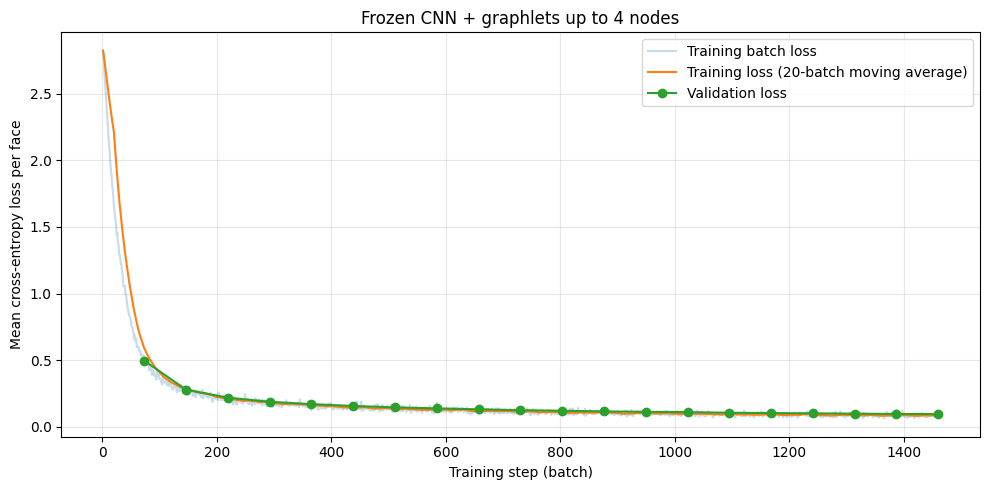

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} CNN + graphlets up to {max_graphlet_nodes} nodes")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()

### 6.2 Accuracy and per-class IoU for the current run

Saved predictions provide loss, accuracy, and intersection over union (IoU)
for all three splits. IoU is `TP / (TP + FP + FN)`, with counts aggregated
across all faces in each split. Mean IoU gives each class equal weight,
includes stock, and excludes classes with zero union.

This report reads cached predictions without inference. After a kernel restart,
run the imports and configuration cells in section 1, then this cell; encoder
loading and data preparation are not required. Prediction files for all three
splits must be available at the selected epoch. Set `report_checkpoint_dir`
to inspect another completed run.

In [17]:
# Choose the saved epoch to analyse.
report_checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"Missing {prediction_path}. Run final evaluation for all three splits first."
        )

class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

class_rows = []
summary_rows = []
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    results = torch.load(prediction_path, map_location="cpu", weights_only=True)
    labels = results["labels"].long()
    predictions = results["predictions"].long()
    num_classes = results["probabilities"].shape[1]
    confusion = torch.bincount(
        labels * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    intersection = confusion.diag()
    union = confusion.sum(1) + confusion.sum(0) - intersection
    # Leave out classes with no true or predicted faces when averaging IoU.
    iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
    summary_rows.append({
        "split": split,
        "solids": len(results["sample_ids"]),
        "faces": labels.numel(),
        "loss": results["loss"],
        "accuracy": intersection.sum().item() / labels.numel(),
        "mean_iou": iou.nanmean().item(),
    })
    for index in range(num_classes):
        class_rows.append({
            "split": split, "class_index": index,
            "class_name": class_names.get(index, str(index)),
            "support": confusion[index].sum().item(),
            "intersection": intersection[index].item(),
            "union": union[index].item(), "iou": iou[index].item(),
        })

summary = pd.DataFrame(summary_rows).set_index("split")
per_class_iou = pd.DataFrame(class_rows)
display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
display(per_class_iou.pivot(index=["class_index", "class_name"],
                           columns="split", values="iou").style.format("{:.2%}"))
summary.to_csv(report_checkpoint_dir / "iou_summary.csv")
per_class_iou.to_csv(report_checkpoint_dir / "per_class_iou.csv", index=False)

,solids,faces,loss,accuracy,mean_iou
split,,,,,
train,9277,209847,0.0830,97.02%,93.27%
validation,3090,70255,0.0948,96.57%,92.44%
test,3094,69411,0.0945,96.55%,92.36%


,split,test,train,validation
class_index,class_name,,,
0,rectangular_through_slot,99.80%,100.00%,99.57%
1,triangular_through_slot,95.26%,96.54%,96.24%
2,rectangular_passage,82.03%,84.63%,81.92%
3,triangular_passage,92.21%,94.69%,93.63%
4,6sides_passage,99.50%,99.88%,99.47%
5,rectangular_through_step,77.49%,79.10%,77.55%
6,2sides_through_step,86.56%,88.01%,87.24%
7,slanted_through_step,99.54%,99.60%,99.23%
8,rectangular_blind_step,98.88%,99.44%,98.92%


### 6.3 Comparison with geometry-only and graphlet variants

Saved predictions are used to compare the geometry-only model and graphlet
variants with different maximum sizes and training modes. The latest epoch
with both training and validation exports is selected for each variant. Test
scores are included when available at that same epoch, so earlier runs with
only training and validation exports remain visible.

Epoch, loss, accuracy, mean IoU, and per-class metrics are reported without
training or inference. Mean IoU includes stock. This comparison does not select
models by validation or test performance and can run independently after a kernel restart.

In [18]:
# Compare cached final predictions across all completed variants.
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
variant_dirs = {
    "Frozen CNN + graphlets 2–4": project_dir / "results/graphlet4_frozen_run_01",
    "Joint CNN + graphlets 2–4": project_dir / "results/graphlet4_joint_run_01",
    "Frozen CNN + graphlets 2–5": project_dir / "results/graphlet5_frozen_run_01",
    "Joint CNN + graphlets 2–5": project_dir / "results/graphlet5_joint_run_01",
    "Geometry only": project_dir / "results/baseline_run_01",
}
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    available_splits = [split for split in ("train", "validation", "test")
                        if (checkpoint_dir / f"{split}_predictions.pt").is_file()]
    for split in available_splits:
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/graphlet_variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/graphlet_variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")

No completed prediction files yet: Frozen CNN + graphlets 2–5
No completed prediction files yet: Joint CNN + graphlets 2–5


Per-class IoU (unweighted class mean above, including stock):


### 6.4 Loss comparison across variants

Epoch-level training and validation losses are read from the saved histories
of the geometry-only model and graphlet variants. The four size/mode combinations
remain separate, and missing runs are skipped. Test scores are not used to
construct training curves. This cell can run independently after a kernel restart.

Not run yet: Frozen CNN + graphlets 2–5


Not run yet: Joint CNN + graphlets 2–5
Saved comparison: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\graphlet_variants_loss.png


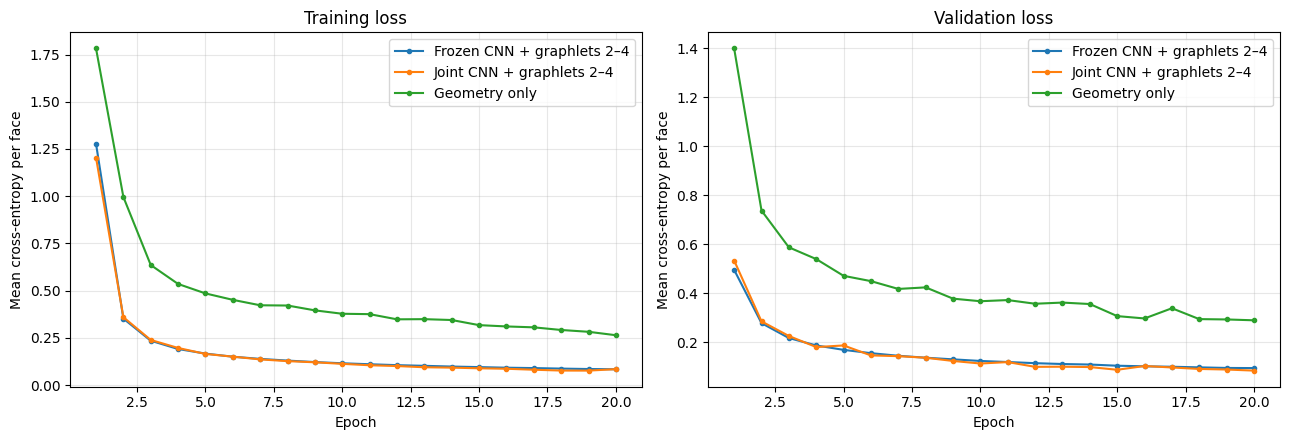

In [19]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent

variants = {
    "Frozen CNN + graphlets 2–4": project_dir / "results/graphlet4_frozen_run_01/history.csv",
    "Joint CNN + graphlets 2–4": project_dir / "results/graphlet4_joint_run_01/history.csv",
    "Frozen CNN + graphlets 2–5": project_dir / "results/graphlet5_frozen_run_01/history.csv",
    "Joint CNN + graphlets 2–5": project_dir / "results/graphlet5_joint_run_01/history.csv",
    "Geometry only": project_dir / "results/baseline_run_01/history.csv",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/graphlet_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()